# W11A A · 이미지·마스크·의미를 한 단계씩 바꾸기

2026-11-09 · 『핸즈온 생성형 AI』8장 · 7장 실습 보완과 연결

새 Colab 사본에서 처음부터 독립 실행합니다. 필수 경로는 CPU입니다. 개인 사진·API 키·유료 GPU·이전 노트북 파일은 필요 없습니다. 패키지0.1.18 / `2026-fall-w11a`에 데이터·사전학습 소형 checkpoint·실제 SD 기록이 포함됩니다. 최초 설치는 네트워크가 필요하며 이후 캐시를 재사용합니다. 실패를 성공 그림으로 대체하지 않습니다.

**현재 실행**은 28×28 class denoiser와 수치 계산입니다. **SD 기록 분석**은 CPU에서 실제 실행해 보관한 SD1.5 결과를 읽습니다. SDXL·T4 현재 실행으로 해석하지 않습니다. 소형 모델과 전체 SD 결과의 품질·속도를 직접 비교하지 않습니다.

각 핵심 코드는 이 화면에 펼쳐 두었습니다. 읽기용 발췌와 import 원본의 SHA를 제작 단계에서 대조합니다. 독립 연습의 `my_...=None`은 다음 셀 실행을 막지 않습니다.

[강의노트](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11a/course/notion/w11a/w11a-lesson.md) · [계산 기록지](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11a/course/notion/w11a/w11a-workbook.md) · [7장 A 개선판](https://colab.research.google.com/github/lunalab-ai/genAI/blob/2026-fall-w11a/notebooks/student/w10b_diffusion_adaptation.ipynb)


In [ ]:
#@title 설치·런타임 준비 { display-mode: "form" }
import sys, subprocess, os, json, uuid
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
PUBLIC_REF='2026-fall-w11a'
try: ready=version('luna-genai')=='0.1.18'
except PackageNotFoundError: ready=False
if not ready:
    if 'luna_genai' in sys.modules: raise RuntimeError('런타임을 재시작하고 첫 셀부터 실행하세요.')
    local=Path('src/pyproject.toml').exists()
    package=str(Path('src').resolve())+'[image-editing]' if local else 'luna-genai[image-editing] @ git+https://github.com/lunalab-ai/genAI.git@'+PUBLIC_REF+'#subdirectory=src'
    subprocess.run([sys.executable,'-m','pip','install','-q']+(['-e'] if local else [])+[package],check=True)
from luna_genai.runtime import prepare_text_runtime
prepare_text_runtime(repair_optional=True)
import torch, numpy as np, pandas as pd
from PIL import Image
from IPython.display import display
torch.set_num_threads(4)
IN_COLAB='COLAB_RELEASE_TAG' in os.environ
RUN_ID=uuid.uuid4().hex[:8]
print('Python',sys.version.split()[0],'package',version('luna-genai'),'CUDA',torch.cuda.is_available())


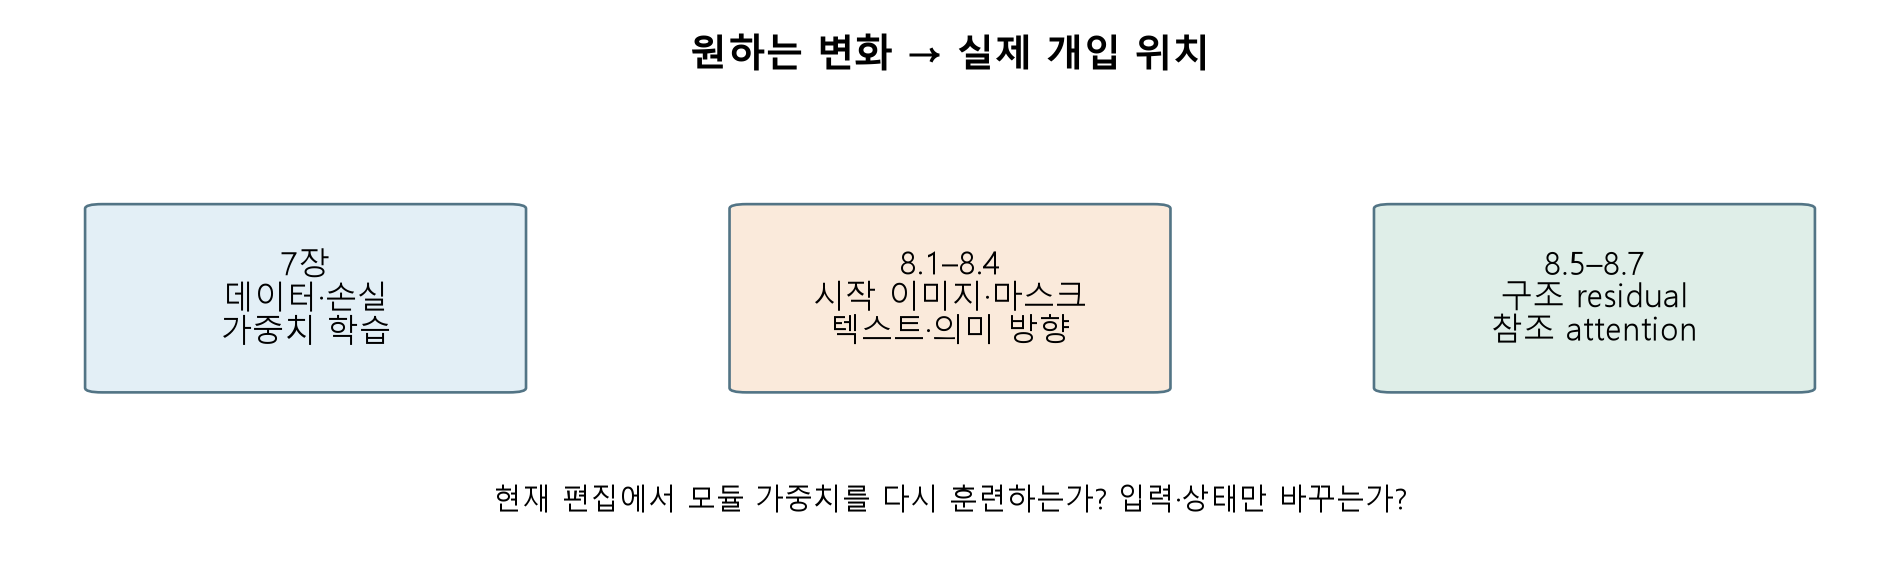


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w11a/course/notion/w11a/assets/01-intervention-map.png)


## 1. 가중치를 다시 학습하는가? 시작 상태를 바꾸는가?

7장의 `optimizer.step()`은 가중치를 바꿉니다. 여기의 image2image는 같은 가중치에서 시작 이미지를 noise와 섞고 일부 denoising 구간만 실행합니다. 소형 모델의 입력은 `[B,1,28,28]`, class8은 Bag입니다. 텍스트를 학습하는 SD가 아닙니다.

$$x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$$

예: $\bar\alpha_t=.64,x_0=.5,\epsilon=-1$이면 $x_t=.8(.5)+.6(-1)=-.2$입니다. strength는 이 식의 가중치 그 자체가 아니라 **시작 timestep을 선택하는 인자**입니다.


**실제 구현 펼쳐 보기 · `tiny_edit`**

[고정 버전 정의](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11a/src/luna_genai/image_editing.py#L130) · 아래 코드는 같은 소스에서 자동 발췌한 읽기용 코드입니다. 실행은 import한 원본 함수를 호출합니다.

```python
    scheduler = DDIMScheduler.from_config(make_scheduler().config, timestep_spacing='trailing')
    scheduler.set_timesteps(steps)
    count = min(steps, max(1, int(steps * strength))) if strength > 0 else 0
    times = scheduler.timesteps[-count:] if count else scheduler.timesteps[:0]
    noise = torch.randn(clean.shape, generator=torch.Generator().manual_seed(seed))
    x = scheduler.add_noise(clean, noise, times[:1]) if count else clean.clone()
    initial = x.clone(); trace = []; mode = model.training; model.eval()
```


**실제 구현 펼쳐 보기 · `tiny_edit`**

[고정 버전 정의](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11a/src/luna_genai/image_editing.py#L138) · 아래 코드는 같은 소스에서 자동 발췌한 읽기용 코드입니다. 실행은 import한 원본 함수를 호출합니다.

```python
        for i, t in enumerate(times):
            predicted = model(x, torch.full((len(x),), int(t), dtype=torch.long), torch.full((len(x),), label, dtype=torch.long))
            x = scheduler.step(predicted, t, x, eta=0).prev_sample
            if mask is not None:
                kept = scheduler.add_noise(clean, noise, times[i + 1:i + 2]) if i + 1 < count else clean
                x = mask * x + (1 - mask) * kept
            trace.append({'t': int(t), 'epsilon_rms': float(predicted.square().mean().sqrt()), 'x_rms': float(x.square().mean().sqrt())})
```


In [ ]:
from luna_genai.diffusion_adaptation import TinyAdaptationLab,load_teaching_images,parameter_fingerprint
from luna_genai.image_editing import tiny_edit,blend_mask,region_mse,semantic_delta,weighted_embedding,load_edit_records
lab=TinyAdaptationLab('frozen'); clean=load_teaching_images()['train'][:1]
weights_before=parameter_fingerprint(lab.model)
strengths=[0.,.25,.75]
results=[tiny_edit(lab.model,clean,strength=s,steps=20,seed=42) for s in strengths]
display(pd.DataFrame([{'strength':s,'actual_steps':r['executed_steps'],'start_rms':float(r['initial'].square().mean().sqrt()),'change_MSE':float((r['images']-clean).square().mean())} for s,r in zip(strengths,results)]))
for r in results:
    display(Image.fromarray(np.rint((r['images'][0,0].clamp(-1,1).numpy()+1)*127.5).astype('uint8')).resize((224,224)))
display(pd.DataFrame(results[-1]['trace']).head())
my_noisy_pixel=None;my_strength_prediction=None


### 8A1 · 시작 noise와 실행 구간

새 사례: alpha_bar=.36, clean=-.5, noise=1일 때 noisy pixel을 계산하세요. steps20에서 strength .25와 .75의 실제 호출 수를 예상한 뒤 표와 비교하세요. 어느 쪽이 항상 더 좋은가요?

힌트: 제곱근 계수와 strength를 구별하세요.

자가 점검: 예측·관측·통제 조건·한계를 각각 한 문장으로 적으세요.


## 2. 마스크는 ‘어디를 편집할지’ 정한다

흰색1은 편집, 검정0은 유지 의도입니다. 아래 `blend_mask`는 **최종 결과를 합성하는 함수**라 검정 영역이 정확히 보존됩니다. Diffusers inpainting만 호출하면 VAE 재구성 등으로 바깥 영역도 달라질 수 있습니다.

$$y=(1-m)x+m\tilde x$$

한 픽셀 원본 .2, 편집 .8, mask .25이면 .35입니다. 회색 mask는 선형 혼합입니다. 9채널 SDXL inpaint는 noisy latent4 + mask1 + masked-image latent4로 구성하며 아래 소형 pixel 모델과 다릅니다.


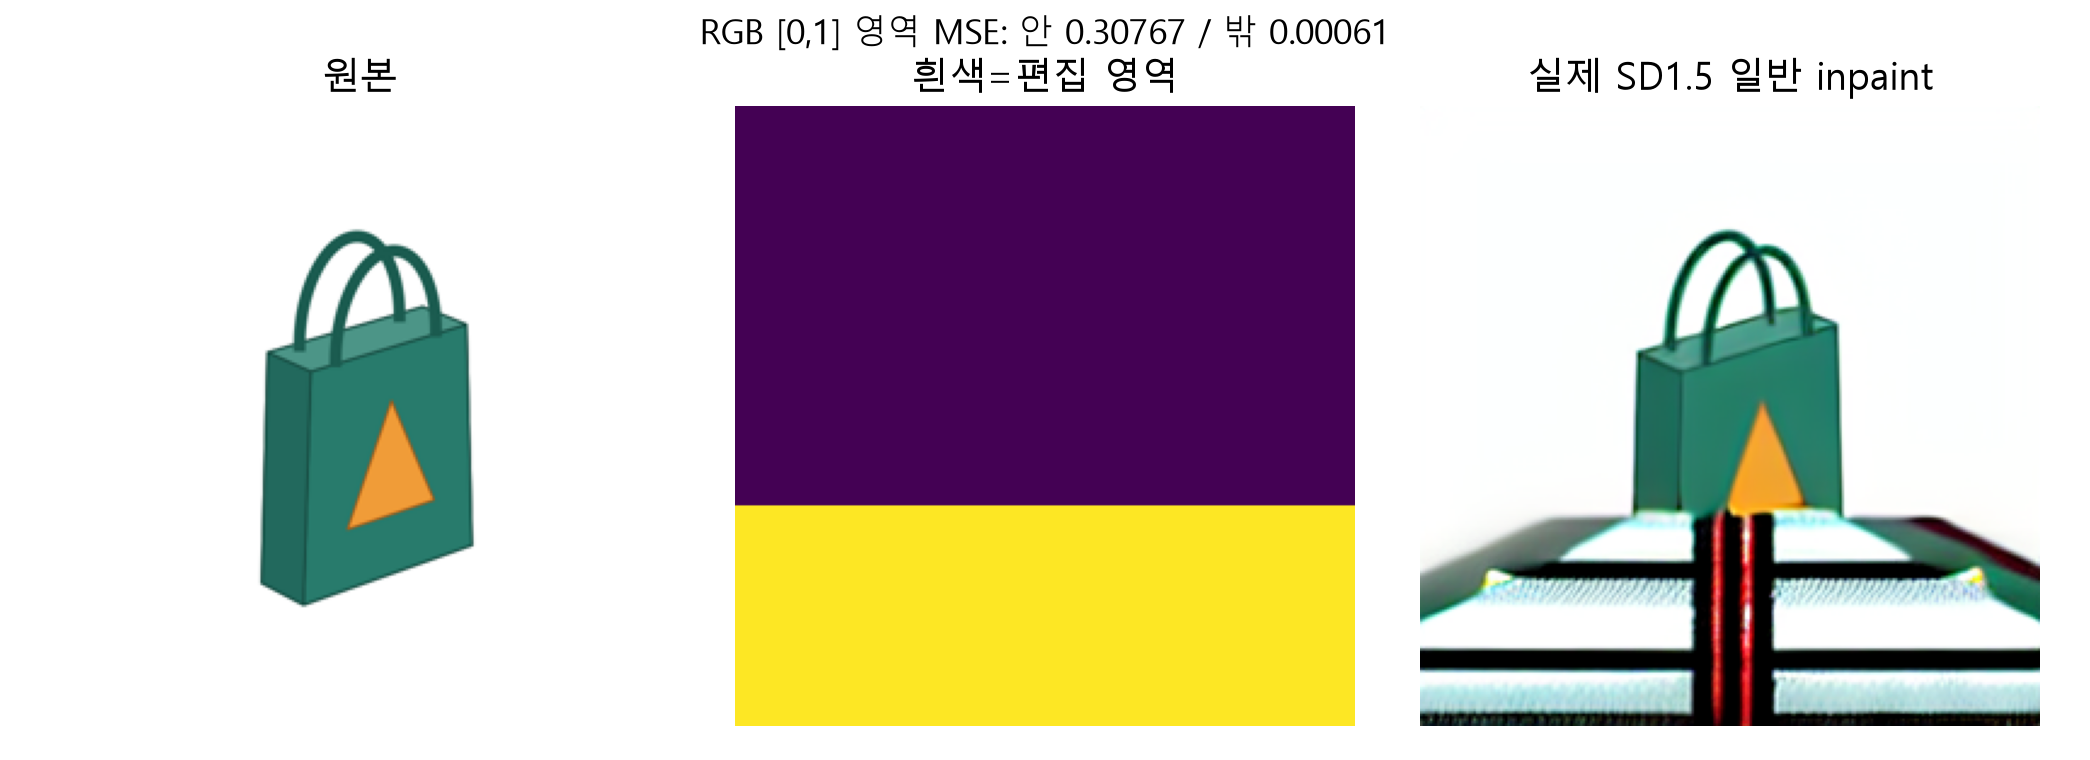


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w11a/course/notion/w11a/assets/04-mask.png)


**실제 구현 펼쳐 보기 · `blend_mask`**

[고정 버전 정의](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11a/src/luna_genai/image_editing.py#L20) · 아래 코드는 같은 소스에서 자동 발췌한 읽기용 코드입니다. 실행은 import한 원본 함수를 호출합니다.

```python
def blend_mask(original: np.ndarray, edited: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """Float arrays [H,W,C], mask [H,W] in [0,1]; white selects edited pixels.

    Returns a new float array. This explicit output overlay preserves black
    pixels exactly; a diffusion inpainting pipeline by itself need not do so.
    """
    a, b, m = np.asarray(original, float), np.asarray(edited, float), np.asarray(mask, float)
    if a.shape != b.shape or a.ndim != 3 or m.shape != a.shape[:2]:
        raise ValueError('Expected equal HWC images and an HW mask')
    if not all(np.isfinite(x).all() for x in (a, b, m)) or (m < 0).any() or (m > 1).any():
        raise ValueError('Finite values and mask in [0,1] required')
    return (1 - m[..., None]) * a + m[..., None] * b
```


In [ ]:
original=np.full((2,2,1),.2);edited=np.full((2,2,1),.8)
mask=np.array([[0.,1.],[.25,.75]])
blended=blend_mask(original,edited,mask)
display(blended[:,:,0]);my_blend=None
binary=torch.zeros_like(clean);binary[:,:,8:23,8:23]=1
masked=tiny_edit(lab.model,clean,strength=.75,steps=20,mask=binary)
metrics=region_mse(clean[0].permute(1,2,0).numpy(),masked['images'][0].permute(1,2,0).numpy(),binary[0,0].numpy())
print('명시적 pixel 복원 helper의 측정:',metrics)
records=load_edit_records(); directory=records['directory']
for name in ['source.png','mask.png','inpaint.png']:display(Image.open(directory/name))
inpaint_record=next(x for x in records['manifest']['records'] if x['id']=='inpaint')
print('전체 SD 실제 기록의 바깥 영역 MSE:',inpaint_record['region_mse'])


### 8A2 · 마스크 반전 오류 찾기

원본 .1, 편집 .9, mask .75를 수계산하세요. 아래 잘못된 식 `mask*original+(1-mask)*edited`를 수정하고 0/1끝점 두 개로 검증하세요. SD 바깥 영역 변화가 helper 버그와 같은 문제인지 설명하세요.

힌트: mask1에 편집값이 나와야 합니다.

자가 점검: 예측·관측·통제 조건·한계를 각각 한 문장으로 적으세요.


## 3. 텍스트와 의미 방향을 바꾸기

Prompt weighting은 어떤 조건을 더 강조하려는 도구입니다. ‘고양이1.5’는 고양이 면적150%라는 뜻이 아닙니다. 아래는 고정 token-feature 텐서를 선형 결합하는 **교육용 계산**입니다. Compel의 구문 분석·분할·AND 연산 전체를 복제하지 않습니다.

Prompt-to-Prompt는 denoising 중 cross-attention map을 재사용/교체하여 배치 보존을 시도합니다. SEGA는 noise prediction 사이의 의미 방향을 선택·가감합니다. 둘은 개입 위치가 다릅니다. Attend-and-Excite는 약한 token attention을 보강해 누락을 줄이려는 방법입니다.

$$d=\epsilon_{concept}-\epsilon_{base},\qquad \epsilon'=\epsilon_{base}+s\,d_{selected}$$


**실제 구현 펼쳐 보기 · `semantic_delta`**

[고정 버전 정의](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11a/src/luna_genai/image_editing.py#L74) · 아래 코드는 같은 소스에서 자동 발췌한 읽기용 코드입니다. 실행은 import한 원본 함수를 호출합니다.

```python
    direction = concept - base
    threshold = torch.quantile(direction.abs().float(), quantile)
    selected = torch.where(direction.abs() >= threshold, direction, 0.)
    delta = (-1 if reverse else 1) * scale * selected
    return {'direction': direction, 'threshold': threshold, 'delta': delta, 'guided': base + delta}
```


**실제 구현 펼쳐 보기 · `weighted_embedding`**

[고정 버전 정의](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11a/src/luna_genai/image_editing.py#L48) · 아래 코드는 같은 소스에서 자동 발췌한 읽기용 코드입니다. 실행은 import한 원본 함수를 호출합니다.

```python
def weighted_embedding(embeddings: torch.Tensor, weights: torch.Tensor) -> torch.Tensor:
    """Teaching linear combination [K,T,D], [K] -> [T,D], not a Compel parser.

    Weights are coefficients, not probabilities or object-area percentages.
    No normalization is applied, no tokens parsed, no model state changed.
    """
    if embeddings.ndim != 3 or weights.shape != (len(embeddings),):
        raise ValueError('Expected KTD embeddings and K coefficients')
    if not torch.isfinite(embeddings).all() or not torch.isfinite(weights).all():
        raise ValueError('Finite embeddings/coefficients required')
    return (embeddings * weights[:, None, None]).sum(dim=0)
```


In [ ]:
emb=torch.tensor([[[1.,0.]],[[0.,2.]]]);weights=torch.tensor([.75,.25])
print('교육용 선형 embedding',weighted_embedding(emb,weights))
base=torch.tensor([1.,1.,1.,1.]);concept=torch.tensor([1.1,1.5,0.,3.])
semantic=semantic_delta(base,concept,scale=2,quantile=.5)
print({k:v.tolist() for k,v in semantic.items()})
for name in ['weighted.png','semantic.png']:display(Image.open(directory/name))
my_reversed=None


### 8A3 · 한 의미 방향만 반전

새 사례 base=[1,2], concept=[3,1], scale=.5, quantile0에서 forward/reverse를 계산하세요. scale0의 결과와 P2P와의 차이를 설명하세요.

힌트: 방향은 concept-base입니다.

자가 점검: 예측·관측·통제 조건·한계를 각각 한 문장으로 적으세요.


## 4. 이미 있는 사진에서 출발하려면: inversion과 instruction

Inversion은 주어진 이미지에 대응하는 latent/noise 경로를 추정합니다. DDIM inversion, Null-text optimization, LEDITS++는 추정/보정 방식이 다릅니다. 텍스트를 바꿔도 원래 구도를 유지하려는 출발점이며 완벽한 복원을 보장하지 않습니다.

InstructPix2Pix는 ‘가방을 빨갛게’처럼 변경 지시와 입력 이미지를 함께 조건으로 사용합니다. CosXL 계열은 교재의 더 큰 별도 backend입니다. 여기 기록은 InstructPix2Pix SD1.5입니다.


In [ ]:
for name in ['source.png','inversion-reconstruction.png','inversion-edit.png','instruction.png']:
    display(Image.open(directory/name))
inverse=next(x for x in records['manifest']['records'] if x['id']=='inversion-reconstruction')
print('실측 재구성 MSE [0,1]:',inverse['reconstruction_mse'])
my_reconstruction_claim=None


### 8A4 · 복원과 편집을 따로 평가

어떤 사진의 재구성 MSE가 .02이고 편집 후 MSE가 .15라면 편집이 실패했다고 단정할 수 있나요? 원본 복원과 편집 지시 성공을 분리해 판정 계획을 적으세요.

힌트: 변경이 목적이라면 원본과 차이가 나는 것이 필요합니다.

자가 점검: 예측·관측·통제 조건·한계를 각각 한 문장으로 적으세요.


In [ ]:
assert parameter_fingerprint(lab.model)==weights_before
assert torch.equal(results[0]['images'],clean)
assert len(results[-1]['trace'])==15 and metrics['outside']==0.
assert all(x['safety_checked'] for x in records['manifest']['records'])
assert np.isfinite(inverse['reconstruction_mse'])
print('W11A_A_RUNTIME_PASS · 실제 pretrained tiny denoising / 마스크·의미계산 / 전체 SD 기록 SHA')
